# Laboratorio 4 · EDA del Proyecto 1 de INVACOM

**Universidad Técnica Nacional · ISW-911 Minería de Datos**

**Integrantes**

- Gaudy Yuliana Chacón Alpizar
- Joab Mauricio Montero Montero
- Ignacio Araya Rojas
- Stuarth Fabricio Miranda Rojas

**Archivo de entrega — lab4_IC2025.ipynb**

Se realiza el análisis exploratorio sobre las fuentes Northwind que el grupo utilizó
en el Proyecto 1 de INVACOM. Se conserva su granularidad de una línea por combinación
de pedido y producto, y se comprueban los importes con las reglas del proyecto.

**Alcance de esta versión.** La indicación recibida para este trabajo es utilizar
el Proyecto 1. Esta selección sustituye la elección de un repositorio de datos
abiertos de Costa Rica descrita en el punto 2 del PDF original.

## 1-3. Fuente del Proyecto 1 y lectura desde Git

Se utilizan las cinco tablas del alcance comercial documentado en TKT-03, TKT-05
y TKT-10 del Proyecto 1. Las fuentes son los CSV suministrados al grupo.

| Archivo | Tabla de preparación del proyecto | Registros esperados |
|---|---|---:|
| order_detail_fresh.csv | INVACOM.NW_ORDER_DETAIL_FRESH | 2.155 |
| order_fresh.csv | INVACOM.NW_ORDER_FRESH | 830 |
| product.csv | INVACOM.NW_PRODUCT | 77 |
| customer.csv | INVACOM.NW_CUSTOMER | 91 |
| category.csv | INVACOM.NW_CATEGORY | 8 |

[Proyecto 1 del equipo](https://github.com/joab1310/invacom-data-warehouse) ·
[Repositorio público del Workshop 4](https://github.com/nachoar24/workshop-4-mineria-datos).

El notebook descarga estas fuentes de un commit fijo del repositorio público.
Cada archivo completo se verifica por SHA-256. Se verificaron además las huellas
de detalle, pedidos y productos contra TKT-10. Northwind es un escenario ficticio
de ejemplo, como documenta [Microsoft](https://learn.microsoft.com/en-us/power-apps/maker/canvas-apps/northwind-install).
El análisis selecciona los campos comerciales del Proyecto 1 y mantiene disponibles
los CSV completos para reproducir las uniones y revisar el resto de atributos.

In [1]:
# Integrantes: Gaudy Yuliana Chacón Alpizar, Joab Mauricio Montero Montero,
# Ignacio Araya Rojas y Stuarth Fabricio Miranda Rojas.
import hashlib
import io
import re
import unicodedata
import urllib.request
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

%matplotlib inline
pd.set_option("display.max_columns", 22)
pd.set_option("display.max_rows", 25)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
AZUL, NARANJA = "#25798c", "#c77735"

In [2]:
URL_BASE_GIT = 'https://raw.githubusercontent.com/nachoar24/workshop-4-mineria-datos/c19bca00ceda799a7b4abc94b45a71cb753d1d3c/datos/northwind/'
HASHES = {'order_detail_fresh.csv': 'c3ff191cf94ae777ed07e8633f1afd82328e1942a876a9d0df4648b3bbd35ce8', 'order_fresh.csv': '2031d20fc764e018df5f86277dd2c4073791d1f719e3460cf182942fc8793cc4', 'product.csv': '4cb2fd1cb5e69038404aca318884761fdfbd3e3465705c26a68272e09069ca8c', 'customer.csv': 'a6c70d4341c87e096fcbc7a792a047159fcb5f54da2d981e17e02f324d39b2dd', 'category.csv': '204f3b0c3eedd8a1ec4c121f2f81cc48a04a75225035192f4182f3679cf6566e'}
CONTEOS = {"order_detail_fresh.csv": 2155, "order_fresh.csv": 830,
            "product.csv": 77, "customer.csv": 91, "category.csv": 8}
tablas = {}
for archivo, huella in HASHES.items():
    peticion = urllib.request.Request(URL_BASE_GIT + archivo,
                                     headers={"User-Agent": "Workshop4-UTN"})
    with urllib.request.urlopen(peticion, timeout=60) as respuesta:
        contenido = respuesta.read()
    assert hashlib.sha256(contenido).hexdigest() == huella, archivo
    tablas[archivo] = pd.read_csv(io.BytesIO(contenido), dtype="string",
                                 encoding="utf-8-sig", na_values=["NULL", "null", ""])
    assert len(tablas[archivo]) == CONTEOS[archivo]
display(pd.DataFrame([{"archivo": nombre, "filas": len(tabla), "columnas": len(tabla.columns)}
                      for nombre, tabla in tablas.items()]))
print("Las cinco fuentes se leyeron y sus huellas coinciden.")

,archivo,filas,columnas
0,order_detail_fresh.csv,2155,5
1,order_fresh.csv,830,14
2,product.csv,77,10
3,customer.csv,91,11
4,category.csv,8,4


Las cinco fuentes se leyeron y sus huellas coinciden.


In [3]:
detalles = tablas["order_detail_fresh.csv"]
pedidos = tablas["order_fresh.csv"]
productos = tablas["product.csv"]
clientes = tablas["customer.csv"]
categorias = tablas["category.csv"]

# Cada unión exige una sola fila de contexto por clave y conserva las líneas.
datos_origen = detalles.merge(
    pedidos[["orderID", "customerID", "orderDate"]], on="orderID", validate="many_to_one"
).merge(
    productos[["productID", "productName", "categoryID"]], on="productID", validate="many_to_one"
).merge(
    clientes[["customerID", "companyName", "city", "region", "postalCode", "country"]],
    on="customerID", validate="many_to_one"
).merge(
    categorias[["categoryID", "categoryName"]], on="categoryID", validate="many_to_one"
)
assert len(datos_origen) == len(detalles) == 2155
assert not datos_origen.duplicated(["orderID", "productID"]).any()
assert datos_origen["orderID"].nunique() == 830
print("Dataset integrado", datos_origen.shape, "con 830 pedidos y 2.155 líneas únicas.")

Dataset integrado (2155, 15) con 830 pedidos y 2.155 líneas únicas.


## 4. Características principales

Se inspeccionan dimensiones, ejemplos, tipos, valores distintos y estadísticas básicas.
Los CSV se leyeron como texto para conservar los códigos y mostrar explícitamente
sus conversiones posteriores. Los estadísticos numéricos se presentan después de
convertir los tipos.

In [4]:
print("Filas y columnas", datos_origen.shape)
display(datos_origen.head())
display(datos_origen.tail(3))
display(datos_origen.sample(3, random_state=42))
datos_origen.info()
display(datos_origen.describe(include="all").T)
display(datos_origen.nunique().rename("valores_distintos").to_frame())
print("Claves de línea duplicadas", datos_origen.duplicated(["orderID", "productID"]).sum())

Filas y columnas (2155, 15)


,orderID,productID,unitPrice,quantity,discount,customerID,orderDate,productName,categoryID,companyName,city,region,postalCode,country,categoryName
0,10248,11,14,12,0,VINET,04-Jul-1996,Queso Cabrales,4,Vins et alcools Chevalier,Reims,<NA>,51100,France,Dairy Products
1,10248,42,9.8,10,0,VINET,04-Jul-1996,Singaporean Hokkien Fried Mee,5,Vins et alcools Chevalier,Reims,<NA>,51100,France,Grains/Cereals
2,10248,72,34.8,5,0,VINET,04-Jul-1996,Mozzarella di Giovanni,4,Vins et alcools Chevalier,Reims,<NA>,51100,France,Dairy Products
3,10249,14,18.6,9,0,TOMSP,05-Jul-1996,Tofu,7,Toms Spezialitäten,Münster,<NA>,44087,Germany,Produce
4,10249,51,42.4,40,0,TOMSP,05-Jul-1996,Manjimup Dried Apples,7,Toms Spezialitäten,Münster,<NA>,44087,Germany,Produce


,orderID,productID,unitPrice,quantity,discount,customerID,orderDate,productName,categoryID,companyName,city,region,postalCode,country,categoryName
2152,11077,73,15,2,0.01,RATTC,06-May-1998,Röd Kaviar,8,Rattlesnake Canyon Grocery,Albuquerque,NM,87110,USA,Seafood
2153,11077,75,7.75,4,0,RATTC,06-May-1998,Rhönbräu Klosterbier,1,Rattlesnake Canyon Grocery,Albuquerque,NM,87110,USA,Beverages
2154,11077,77,13,2,0,RATTC,06-May-1998,Original Frankfurter grüne Soße,2,Rattlesnake Canyon Grocery,Albuquerque,NM,87110,USA,Condiments


,orderID,productID,unitPrice,quantity,discount,customerID,orderDate,productName,categoryID,companyName,city,region,postalCode,country,categoryName
1506,10826,31,12.5,35,0,BLONP,12-Jan-1998,Gorgonzola Telino,4,Blondesddsl père et fils,Strasbourg,<NA>,67000,France,Dairy Products
1917,10990,34,14,60,0.15,ERNSH,01-Apr-1998,Sasquatch Ale,1,Ernst Handel,Graz,<NA>,8010,Austria,Beverages
889,10580,14,23.25,15,0.05,OTTIK,26-Jun-1997,Tofu,7,Ottilies Käseladen,Köln,<NA>,50739,Germany,Produce


<class 'pandas.DataFrame'>
RangeIndex: 2155 entries, 0 to 2154
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   orderID       2155 non-null   string
 1   productID     2155 non-null   string
 2   unitPrice     2155 non-null   string
 3   quantity      2155 non-null   string
 4   discount      2155 non-null   string
 5   customerID    2155 non-null   string
 6   orderDate     2155 non-null   string
 7   productName   2155 non-null   string
 8   categoryID    2155 non-null   string
 9   companyName   2155 non-null   string
 10  city          2155 non-null   string
 11  region        826 non-null    string
 12  postalCode    2100 non-null   string
 13  country       2155 non-null   string
 14  categoryName  2155 non-null   string
dtypes: string(15)
memory usage: 252.7 KB


,count,unique,top,freq
orderID,2155,830,11077,25
productID,2155,77,59,54
unitPrice,2155,116,18,102
quantity,2155,55,20,252
discount,2155,11,0,1317
customerID,2155,89,SAVEA,116
orderDate,2155,480,06-May-1998,32
productName,2155,77,Raclette Courdavault,54
categoryID,2155,8,1,404
companyName,2155,89,Save-a-lot Markets,116


,valores_distintos
orderID,830
productID,77
unitPrice,116
quantity,55
discount,11
customerID,89
orderDate,480
productName,77
categoryID,8
companyName,89


Claves de línea duplicadas 0


## 5. Renombrado de columnas a español

Los identificadores y nombres de campos se traducen al vocabulario del Proyecto 1.
El precio unitario utilizado es el registrado en la línea del pedido.

In [5]:
nombres_espanol = {
    "orderID": "id_pedido", "productID": "id_producto", "unitPrice": "precio_unitario",
    "quantity": "cantidad_vendida", "discount": "tasa_descuento", "customerID": "id_cliente",
    "orderDate": "fecha_pedido", "productName": "producto", "categoryID": "id_categoria",
    "companyName": "cliente", "city": "ciudad_cliente", "region": "region_cliente",
    "postalCode": "codigo_postal_cliente", "country": "pais_cliente", "categoryName": "categoria",
}
display(pd.DataFrame(nombres_espanol.items(), columns=["nombre_original", "nombre_espanol"]))
datos = datos_origen.rename(columns=nombres_espanol).copy()
datos = datos.apply(lambda columna: columna.str.strip()).replace(r"^\s*$", pd.NA, regex=True)
assert datos.columns.is_unique

,nombre_original,nombre_espanol
0,orderID,id_pedido
1,productID,id_producto
2,unitPrice,precio_unitario
3,quantity,cantidad_vendida
4,discount,tasa_descuento
5,customerID,id_cliente
6,orderDate,fecha_pedido
7,productName,producto
8,categoryID,id_categoria
9,companyName,cliente


## 6. Detección de nulos con evidencia gráfica

Se distinguen los campos comerciales obligatorios de los atributos de localización.
El diagnóstico TKT-05 del Proyecto 1 encontró los campos comerciales completos.
Aquí se incluyen región y código postal del cliente para revisar también esas ausencias.
Un nulo de región no demuestra que el país correspondiente utilice esa división
administrativa, por lo que se representará con una categoría explícita.

,cantidad,porcentaje
id_pedido,0,0.000000
id_producto,0,0.000000
precio_unitario,0,0.000000
cantidad_vendida,0,0.000000
tasa_descuento,0,0.000000
id_cliente,0,0.000000
fecha_pedido,0,0.000000
producto,0,0.000000
id_categoria,0,0.000000
cliente,0,0.000000


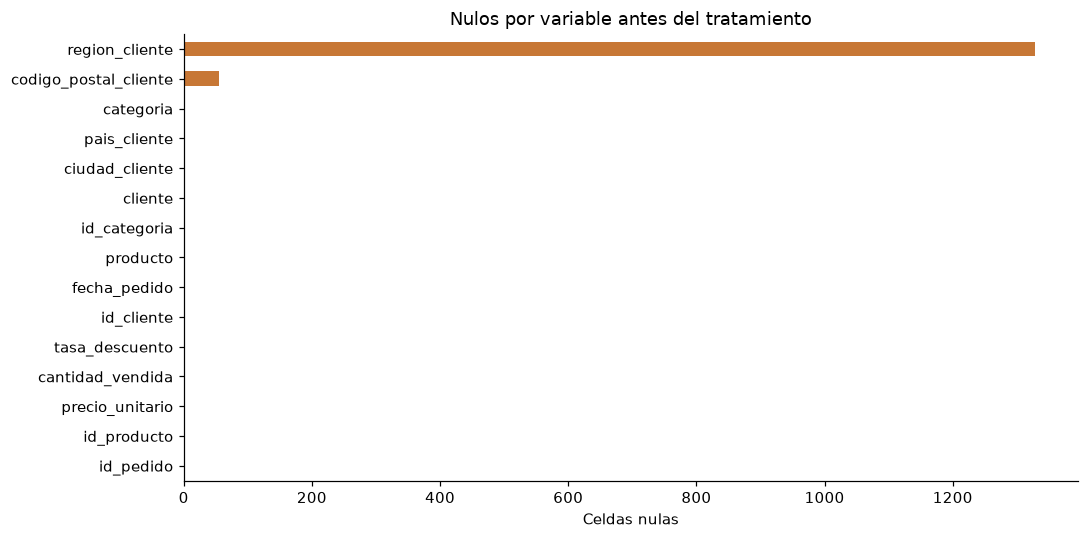

Total de celdas nulas 1384


In [6]:
nulos_antes = datos.isna().sum()
informe_nulos = pd.DataFrame({"cantidad": nulos_antes,
                             "porcentaje": nulos_antes / len(datos) * 100})
display(informe_nulos)
fig, eje = plt.subplots(figsize=(10, 5))
nulos_antes.sort_values().plot.barh(ax=eje, color=NARANJA)
eje.set(title="Nulos por variable antes del tratamiento", xlabel="Celdas nulas", ylabel="")
fig.tight_layout()
plt.show()
print("Total de celdas nulas", int(nulos_antes.sum()))

## 9. Conversión de tipos para el análisis numérico

Se adelantan las conversiones necesarias para detectar los atípicos del punto 7.
Cantidad se convierte a entero, precio y tasa de descuento a decimales, y la fecha
del pedido a datetime. Los identificadores y códigos postales se conservan como
etiquetas en esta etapa. Se validan cantidades positivas, precios no negativos y
descuentos entre 0 y 1, siguiendo las reglas documentadas del Proyecto 1.

In [7]:
datos["cantidad_vendida"] = pd.to_numeric(datos["cantidad_vendida"], errors="raise").astype("int32")
for columna in ["precio_unitario", "tasa_descuento"]:
    datos[columna] = pd.to_numeric(datos[columna], errors="raise").astype("float64")
datos["fecha_pedido"] = pd.to_datetime(datos["fecha_pedido"], format="%d-%b-%Y", errors="raise")
assert datos["cantidad_vendida"].gt(0).all()
assert datos["precio_unitario"].ge(0).all()
assert datos["tasa_descuento"].between(0, 1).all()
datos["ano"] = datos["fecha_pedido"].dt.year
datos["mes"] = datos["fecha_pedido"].dt.month
datos["dia_semana"] = datos["fecha_pedido"].dt.dayofweek
display(datos.dtypes.to_frame("tipo"))
display(datos[["cantidad_vendida", "precio_unitario", "tasa_descuento"]].describe())
print("Período", datos["fecha_pedido"].min().date(), "a", datos["fecha_pedido"].max().date())

,tipo
id_pedido,string
id_producto,string
precio_unitario,float64
cantidad_vendida,int32
tasa_descuento,float64
id_cliente,string
fecha_pedido,datetime64[us]
producto,string
id_categoria,string
cliente,string


,cantidad_vendida,precio_unitario,tasa_descuento
count,2155.000000,2155.000000,2155.000000
mean,23.812993,26.218520,0.056167
std,19.022047,29.827418,0.083450
min,1.000000,2.000000,0.000000
25%,10.000000,12.000000,0.000000
50%,20.000000,18.400000,0.000000
75%,30.000000,32.000000,0.100000
max,130.000000,263.500000,0.250000


Período 1996-07-04 a 1998-05-06


## 7. Valores atípicos con evidencia gráfica

Se utiliza IQR para señalar observaciones fuera de Q1 − 1,5 × IQR y Q3 + 1,5 × IQR.
Un pedido de muchas unidades o un producto caro puede ser comercialmente válido.
Se conservan estos valores y se informa su cantidad. La cantidad vendida será la
variable dependiente, por lo que reemplazar sus valores altos alteraría el fenómeno
de demanda que se pretende estudiar.

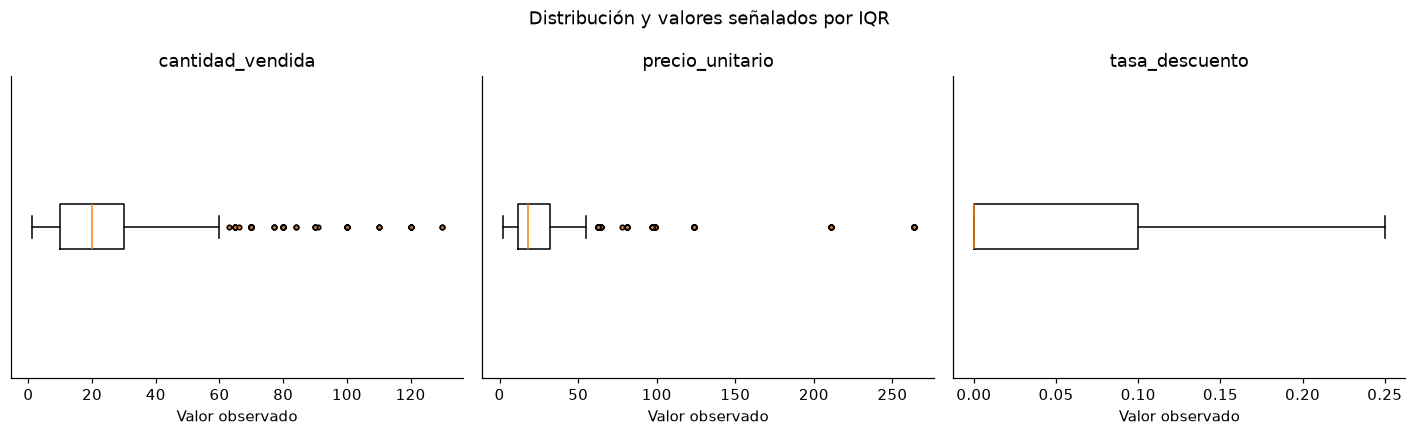

,variable,inferior,superior,atipicos
0,cantidad_vendida,-20.00,60.00,87
1,precio_unitario,-18.00,62.00,98
2,tasa_descuento,-0.15,0.25,0


In [8]:
def detectar_atipicos_iqr(serie):
    '''Identifica observaciones extremas de una medida comercial sin modificarlas.'''
    q1, q3 = serie.dropna().quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((serie < inferior) | (serie > superior)).fillna(False), inferior, superior

medidas = ["cantidad_vendida", "precio_unitario", "tasa_descuento"]
informe_atipicos = []
fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
for eje, columna in zip(ejes, medidas):
    marca, inferior, superior = detectar_atipicos_iqr(datos[columna])
    informe_atipicos.append({"variable": columna, "inferior": inferior, "superior": superior,
                             "atipicos": int(marca.sum())})
    eje.boxplot(datos[columna].dropna(), orientation="horizontal",
                flierprops={"markersize": 3, "markerfacecolor": NARANJA})
    eje.set(title=columna, xlabel="Valor observado", yticks=[])
fig.suptitle("Distribución y valores señalados por IQR")
fig.tight_layout()
plt.show()
display(pd.DataFrame(informe_atipicos))

## 8. Funciones de imputación y justificación

Para categorías ausentes se utiliza **Sin información**, conservando el desconocimiento
del dato. La función numérica usa la mediana por su menor sensibilidad a valores
extremos. Los campos numéricos de este dataset están completos y esa función
registra cero cambios al aplicarse.

Las claves y la fecha del pedido se validan como obligatorias. Los atípicos IQR
conservan su valor al cumplir los rangos de negocio. Las decisiones de preparación
se aplican a esta copia analítica de los CSV del Proyecto 1.

,imputaciones_numericas
cantidad_vendida,0
precio_unitario,0
tasa_descuento,0


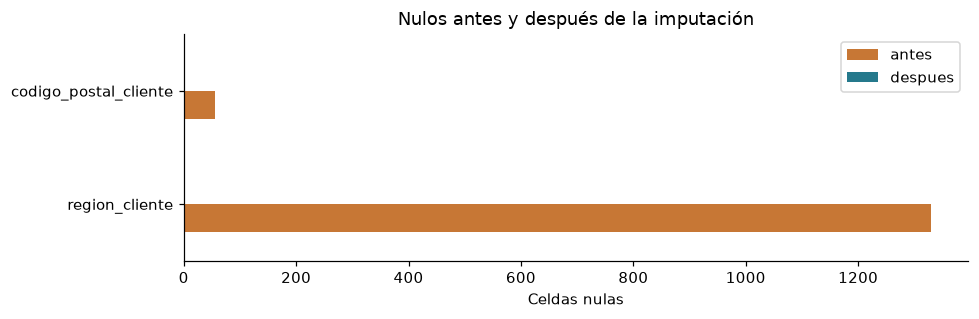

In [9]:
def imputar_categoricas(tabla, columnas):
    '''Representa las ausencias con una etiqueta explícita.'''
    resultado = tabla.copy()
    resultado[columnas] = resultado[columnas].fillna("Sin información")
    return resultado

def imputar_numericas_mediana(tabla, columnas):
    '''Rellena únicamente nulos numéricos y registra cuántos valores cambian.'''
    resultado = tabla.copy()
    cambios = resultado[columnas].isna().sum()
    resultado[columnas] = resultado[columnas].fillna(resultado[columnas].median())
    return resultado, cambios

obligatorias = ["id_pedido", "id_producto", "id_cliente", "fecha_pedido"]
assert not datos[obligatorias].isna().any().any()
categoricas = ["producto", "cliente", "ciudad_cliente", "pais_cliente",
              "region_cliente", "codigo_postal_cliente", "categoria"]
datos_limpios = imputar_categoricas(datos, categoricas)
datos_limpios, cambios_numericos = imputar_numericas_mediana(datos_limpios, medidas)
for columna in categoricas:
    datos_limpios[columna] = datos_limpios[columna].astype("category")
display(cambios_numericos.rename("imputaciones_numericas").to_frame())
comparacion = pd.DataFrame({"antes": nulos_antes,
                            "despues": datos_limpios[nulos_antes.index].isna().sum()})
comparacion.loc[comparacion["antes"] > 0].plot.barh(figsize=(9, 3), color=[NARANJA, AZUL])
plt.title("Nulos antes y después de la imputación")
plt.xlabel("Celdas nulas")
plt.ylabel("")
plt.tight_layout()
plt.show()
assert not datos_limpios.isna().any().any()
pd.testing.assert_frame_equal(datos_limpios[medidas], datos[medidas])

## Relación con las medidas comerciales del Proyecto 1

Se aplica redondeo decimal por línea con ROUND_HALF_UP, compatible con los importes
documentados en el proyecto. Importe bruto = cantidad × precio unitario;
descuento monetario = bruto × tasa de descuento; importe neto = bruto − descuento.
La conciliación verifica tanto las 51.317 unidades como los totales del Proyecto 1.

,total_conciliado
importe_bruto,1354458.59
importe_descuento,88665.83
importe_neto,1265792.76


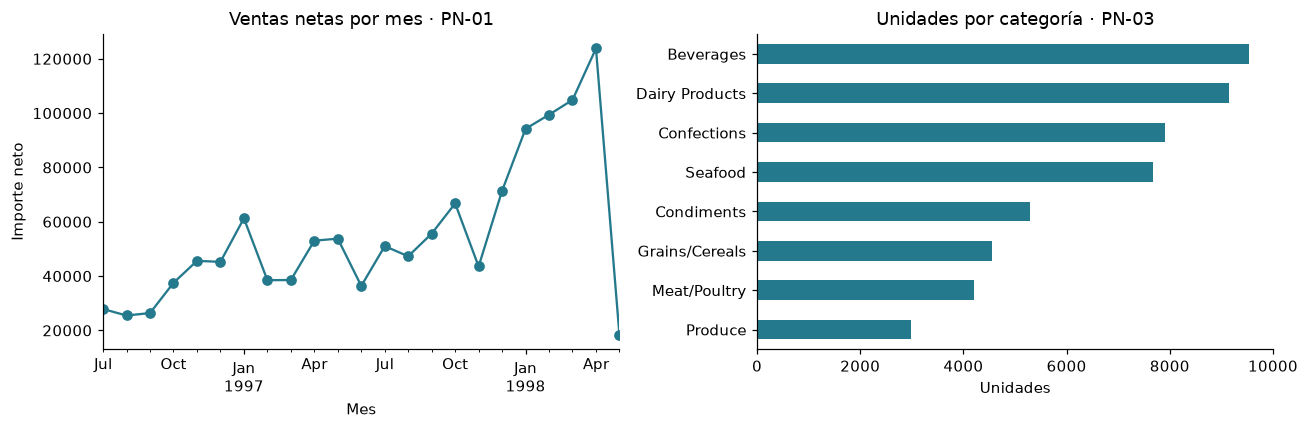

In [10]:
def calcular_importes(fila):
    '''Reproduce el redondeo monetario por línea utilizado en el Proyecto 1.'''
    centimo = Decimal("0.01")
    bruto = (Decimal(str(fila.cantidad_vendida)) * Decimal(str(fila.precio_unitario))).quantize(
        centimo, rounding=ROUND_HALF_UP)
    descuento = (bruto * Decimal(str(fila.tasa_descuento))).quantize(centimo, rounding=ROUND_HALF_UP)
    return float(bruto), float(descuento), float(bruto - descuento)

columnas_importes = ["importe_bruto", "importe_descuento", "importe_neto"]
importes = [calcular_importes(fila) for fila in datos_limpios.itertuples(index=False)]
datos_limpios[columnas_importes] = pd.DataFrame(importes, index=datos_limpios.index)
totales = datos_limpios[columnas_importes].sum().round(2)
assert datos_limpios["cantidad_vendida"].sum() == 51317
assert np.allclose(totales, [1354458.59, 88665.83, 1265792.76], atol=0.001, rtol=0)
display(totales.rename("total_conciliado").to_frame())
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
datos_limpios.groupby(datos_limpios["fecha_pedido"].dt.to_period("M"))["importe_neto"].sum().plot(
    ax=ejes[0], color=AZUL, marker="o")
ejes[0].set(title="Ventas netas por mes · PN-01", xlabel="Mes", ylabel="Importe neto")
datos_limpios.groupby("categoria", observed=True)["cantidad_vendida"].sum().sort_values().plot.barh(
    ax=ejes[1], color=AZUL)
ejes[1].set(title="Unidades por categoría · PN-03", xlabel="Unidades", ylabel="")
fig.tight_layout()
plt.show()

## 10. Codificación de variables categóricas

Producto, categoría y ubicación del cliente se representan mediante one-hot.
Esto permite tratar las etiquetas como nominales. El mes y el día de la semana
se representan con seno y coseno para conservar su ciclo.

Los identificadores de pedido y producto se conservarán para auditoría y conciliación.
Cliente, identificador de cliente y código postal permiten rastrear el registro en
las fuentes. El candidato utilizará los predictores seleccionados que se construyen
a continuación. Su variable dependiente es **cantidad_vendida**.

In [11]:
categoricas_modelo = ["producto", "categoria", "pais_cliente", "ciudad_cliente", "region_cliente"]
indicadores = pd.get_dummies(datos_limpios[categoricas_modelo], prefix_sep="__", dtype="uint8")

def normalizar_nombre(nombre):
    '''Conserva nombres de columnas en español con caracteres aptos para el CSV.'''
    texto = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9_]+", "_", texto.lower()).strip("_")

indicadores.columns = [normalizar_nombre(nombre) for nombre in indicadores.columns]
predictores = datos_limpios[["precio_unitario", "tasa_descuento", "ano"]].copy()
for columna, periodo, inicio in [("mes", 12, 1), ("dia_semana", 7, 0)]:
    angulo = 2 * np.pi * (datos_limpios[columna] - inicio) / periodo
    predictores[columna + "_seno"] = np.sin(angulo)
    predictores[columna + "_coseno"] = np.cos(angulo)
predictores = pd.concat([predictores, indicadores], axis=1)
objetivo = datos_limpios["cantidad_vendida"].copy()
assert predictores.columns.is_unique
print("Matriz de predictores", predictores.shape)
display(predictores.head())

Matriz de predictores (2155, 202)


,precio_unitario,tasa_descuento,ano,mes_seno,mes_coseno,dia_semana_seno,dia_semana_coseno,producto__alice_mutton,producto__aniseed_syrup,producto__boston_crab_meat,producto__camembert_pierrot,...,region_cliente__mt,region_cliente__nm,region_cliente__nueva_esparta,region_cliente__or,region_cliente__quebec,region_cliente__rj,region_cliente__sp,region_cliente__sin_informacion,region_cliente__tachira,region_cliente__wa,region_cliente__wy
0,14.0,0.0,1996,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0
1,9.8,0.0,1996,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0
2,34.8,0.0,1996,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0
3,18.6,0.0,1996,1.224647e-16,-1.0,-0.433884,-0.900969,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0
4,42.4,0.0,1996,1.224647e-16,-1.0,-0.433884,-0.900969,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0


## 11. Estandarización

Se estandarizan precio unitario, tasa de descuento y año mediante StandardScaler,
con media cero y desviación estándar poblacional uno. Sus nombres finales llevan
el sufijo **_z**. Los indicadores binarios y las variables cíclicas conservan sus escalas.
Cantidad vendida conserva la unidad original de la variable dependiente.

El EDA utiliza el conjunto completo. Al evaluar un modelo posterior, la imputación,
la codificación y la estandarización se deben ajustar solamente con entrenamiento.

,media_original,escala_original,media_z,desviacion_z
precio_unitario,26.218520,29.820497,-0.0,1.0
tasa_descuento,0.056167,0.083431,0.0,1.0
ano,1997.132715,0.700694,0.0,1.0


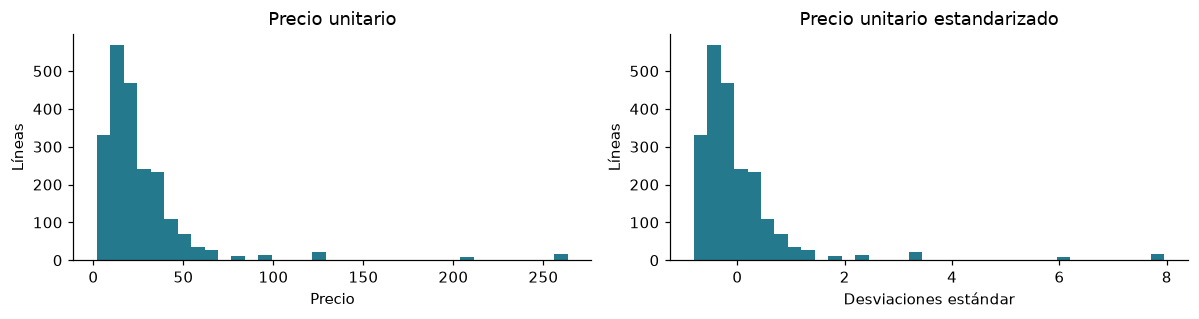

In [12]:
columnas_estandarizar = ["precio_unitario", "tasa_descuento", "ano"]
escalador = StandardScaler()
valores_z = escalador.fit_transform(predictores[columnas_estandarizar])
predictores_z = predictores.drop(columns=columnas_estandarizar).copy()
for posicion, columna in enumerate(columnas_estandarizar):
    predictores_z[columna + "_z"] = valores_z[:, posicion]
parametros = pd.DataFrame({"media_original": escalador.mean_, "escala_original": escalador.scale_,
                           "media_z": valores_z.mean(axis=0), "desviacion_z": valores_z.std(axis=0)},
                          index=columnas_estandarizar)
display(parametros.round(6))
fig, ejes = plt.subplots(1, 2, figsize=(11, 3))
ejes[0].hist(predictores["precio_unitario"], bins=35, color=AZUL)
ejes[0].set(title="Precio unitario", xlabel="Precio", ylabel="Líneas")
ejes[1].hist(predictores_z["precio_unitario_z"], bins=35, color=AZUL)
ejes[1].set(title="Precio unitario estandarizado", xlabel="Desviaciones estándar", ylabel="Líneas")
fig.tight_layout()
plt.show()

## 12. Correlación y evidencia gráfica

Se calcula Pearson sobre las medidas comerciales. Los identificadores se excluyen
de esta interpretación numérica. Las asociaciones entre cantidad, bruto y neto
también reflejan las fórmulas que los relacionan. Por eso los importes calculados
a partir de cantidad no se incluyen entre sus predictores.

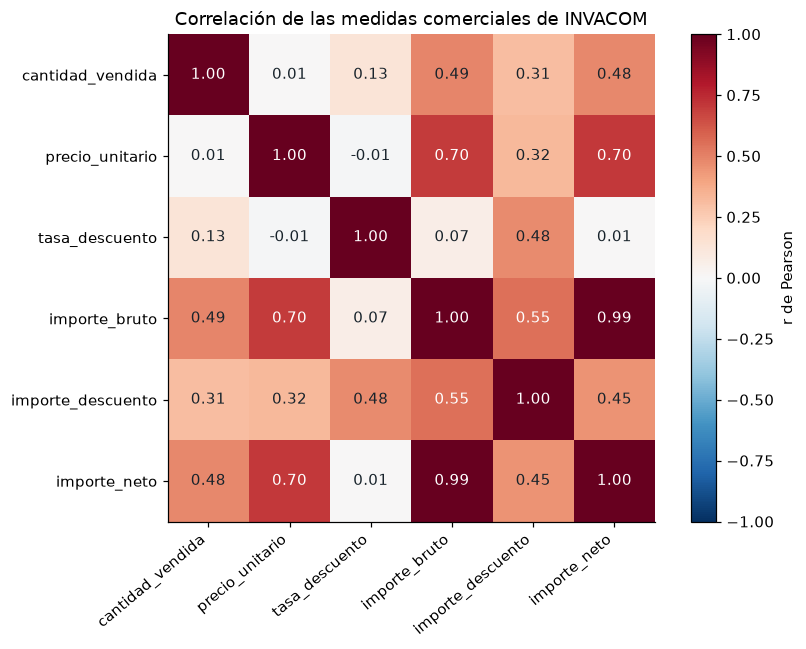

,correlacion
precio_unitario,0.0074
tasa_descuento,0.1286
importe_bruto,0.4887
importe_descuento,0.3091
importe_neto,0.4799


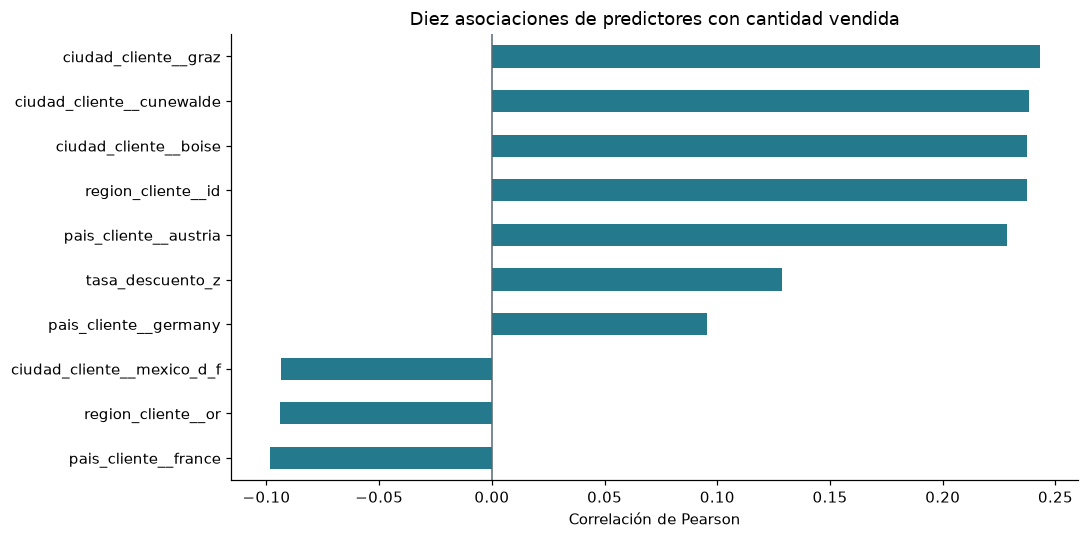

,correlacion
ciudad_cliente__graz,0.2429
ciudad_cliente__cunewalde,0.2385
region_cliente__id,0.2374
ciudad_cliente__boise,0.2374
pais_cliente__austria,0.2286
tasa_descuento_z,0.1286
pais_cliente__france,-0.0985
pais_cliente__germany,0.0953
region_cliente__or,-0.0940
ciudad_cliente__mexico_d_f,-0.0936


In [13]:
columnas_correlacion = ["cantidad_vendida", "precio_unitario", "tasa_descuento",
                        "importe_bruto", "importe_descuento", "importe_neto"]
matriz = datos_limpios[columnas_correlacion].corr()
fig, eje = plt.subplots(figsize=(8, 6))
imagen = eje.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_xticks(range(len(matriz)), matriz.columns, rotation=40, ha="right")
eje.set_yticks(range(len(matriz)), matriz.columns)
for fila in range(len(matriz)):
    for columna in range(len(matriz)):
        valor = matriz.iloc[fila, columna]
        eje.text(columna, fila, f"{valor:.2f}", ha="center", va="center",
                 color="white" if abs(valor) > 0.55 else "#18232b")
eje.set_title("Correlación de las medidas comerciales de INVACOM")
fig.colorbar(imagen, ax=eje, label="r de Pearson")
fig.tight_layout()
plt.show()
display(matriz["cantidad_vendida"].drop("cantidad_vendida").rename("correlacion").to_frame().round(4))
correlaciones = predictores_z.corrwith(objetivo).dropna()
principales = correlaciones.reindex(correlaciones.abs().sort_values(ascending=False).head(10).index)
principales.sort_values().plot.barh(figsize=(10, 5), color=AZUL)
plt.axvline(0, color="#596872", linewidth=1)
plt.title("Diez asociaciones de predictores con cantidad vendida")
plt.xlabel("Correlación de Pearson")
plt.tight_layout()
plt.show()
display(principales.rename("correlacion").to_frame().round(4))

## 13. Variable dependiente y modelo candidato

La variable dependiente propuesta es **cantidad_vendida** por línea de pedido.
Este objetivo se relaciona con el análisis de cantidades por producto y categoría
del Proyecto 1 y permite estudiar un candidato de regresión para la demanda de una línea.

Se propone un **árbol de decisión de regresión** por su capacidad para representar
relaciones no lineales e interacciones entre producto, categoría, ubicación,
precio y condiciones de descuento. Profundidad y tamaño de hoja limitan su complejidad.

Los importes bruto, descuento monetario y neto se reservan para auditoría porque
contienen información calculada a partir de la propia cantidad. Los identificadores
tampoco son predictores. Para una evaluación posterior debe separarse entrenamiento
y prueba por pedido o por fecha, considerando que un mismo pedido tiene varias líneas.
Se pueden utilizar MAE y RMSE para evaluar el error en unidades.

In [14]:
modelo_candidato = DecisionTreeRegressor(max_depth=5, min_samples_leaf=15, random_state=42)
print("Variable dependiente", objetivo.name)
display(objetivo.describe().to_frame())
print(modelo_candidato)
assert "cantidad_vendida" not in predictores_z
assert not set(columnas_importes).intersection(predictores_z.columns)

Variable dependiente cantidad_vendida


,cantidad_vendida
count,2155.000000
mean,23.812993
std,19.022047
min,1.000000
25%,10.000000
50%,20.000000
75%,30.000000
max,130.000000


DecisionTreeRegressor(max_depth=5, min_samples_leaf=15, random_state=42)


## 14. Guardado del conjunto procesado

Se guarda **data_process.csv** con los predictores numéricos preparados, la cantidad
vendida y las columnas de auditoría para conciliar con el Proyecto 1.
Los identificadores y los importes monetarios se conservan en su escala original.
Las columnas de predicción son las de **predictores_z**.

Los parámetros de la sección 11 permiten recuperar las unidades de una columna
estandarizada mediante valor original = valor z × escala original + media original.

In [15]:
auditoria = datos_limpios[["id_pedido", "id_producto"] + columnas_importes].copy()
for columna in ["id_pedido", "id_producto"]:
    auditoria[columna] = pd.to_numeric(auditoria[columna], errors="raise").astype("int32")
datos_procesados = pd.concat([auditoria, predictores_z, objetivo], axis=1)
assert len(datos_procesados) == 2155
assert not datos_procesados.duplicated(["id_pedido", "id_producto"]).any()
assert not datos_procesados.isna().any().any()
assert np.isfinite(datos_procesados.to_numpy(dtype=float)).all()
datos_procesados.to_csv("data_process.csv", index=False, encoding="utf-8", float_format="%.10g")
comprobacion = pd.read_csv("data_process.csv")
assert comprobacion.shape == datos_procesados.shape
assert comprobacion.columns.tolist() == datos_procesados.columns.tolist()
assert np.allclose(comprobacion, datos_procesados, rtol=1e-8, atol=1e-9)
print("Archivo guardado data_process.csv")
print("Dimensiones", datos_procesados.shape)
print("Unidades conciliadas", datos_procesados["cantidad_vendida"].sum())
print("Venta neta conciliada", round(datos_procesados["importe_neto"].sum(), 2))
print("Nulos finales", int(datos_procesados.isna().sum().sum()))
display(datos_procesados.head())

Archivo guardado data_process.csv
Dimensiones (2155, 208)
Unidades conciliadas 51317
Venta neta conciliada 1265792.76
Nulos finales 0


,id_pedido,id_producto,importe_bruto,importe_descuento,importe_neto,mes_seno,mes_coseno,dia_semana_seno,dia_semana_coseno,producto__alice_mutton,producto__aniseed_syrup,...,region_cliente__quebec,region_cliente__rj,region_cliente__sp,region_cliente__sin_informacion,region_cliente__tachira,region_cliente__wa,region_cliente__wy,precio_unitario_z,tasa_descuento_z,ano_z,cantidad_vendida
0,10248,11,168.0,0.0,168.0,1.224647e-16,-1.0,0.433884,-0.900969,0,0,...,0,0,0,1,0,0,0,-0.409736,-0.673216,-1.616562,12
1,10248,42,98.0,0.0,98.0,1.224647e-16,-1.0,0.433884,-0.900969,0,0,...,0,0,0,1,0,0,0,-0.550578,-0.673216,-1.616562,10
2,10248,72,174.0,0.0,174.0,1.224647e-16,-1.0,0.433884,-0.900969,0,0,...,0,0,0,1,0,0,0,0.287771,-0.673216,-1.616562,5
3,10249,14,167.4,0.0,167.4,1.224647e-16,-1.0,-0.433884,-0.900969,0,0,...,0,0,0,1,0,0,0,-0.255479,-0.673216,-1.616562,9
4,10249,51,1696.0,0.0,1696.0,1.224647e-16,-1.0,-0.433884,-0.900969,0,0,...,0,0,0,1,0,0,0,0.542629,-0.673216,-1.616562,40


## 15-16. Integrantes y entrega

El encabezado incluye los cuatro integrantes indicados por el grupo.
El archivo solicitado para el campus es **lab4_IC2025.ipynb**, con las celdas
ejecutadas y las evidencias gráficas. **data_process.csv** contiene el resultado.
Las cinco fuentes originales se encuentran en el repositorio público del Workshop 4.